# AP 155 Lab Exercise
---
## Exercise 9: Interpolation

_Instructions_:
- **Report figures:** Compare the original data with interpolated reconstructions. Include the synthetic sine example and the sampled real-world dataset, if available. For the real-world dataset, compare sampling levels of 50%, 30%, 10%, and 5%.
- **Report discussion:** Explain how the choice of interpolator and sampling level affects the reconstruction. Discuss limitations, including behavior outside the sampled domain.
- **Code:** Complete the code and ensure it is functional, readable, and efficient. Include concise Markdown documentation highlighting the critical steps.

### Student Information
- _Full Name (Last Name, First Name)_: Ricerra, Myke Lawrence
- _Student No._: 2024-07203
- _Section_: THU-TX-1

### Grading Information (c/o Lab Instructor)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figures | XX | 20 |
| Report discussion | XX | 20 |
| Code readability | XX | 20 |
| Code efficiency | XX | 20 |
| Code appropriateness | XX | 20 |
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_

---
## Section 1: Report

### Report figures

<img src="figures/9.1.png" alt=" Synthetic data interpolation of Sine Function" width=60%>

**Figure 1. Synthetic data interpolation of Sine Function.** Sampled sine data with the linear, nearest, quadratic, and cubic interpolations.

<img src="figures/9.2.png" alt=" Synthetic data interpolation of Sine Function" width=60%>

**Figure 2.1. Real-world data reconstruction.** Four reconstruction plots of the Dow Jones time-series dataset at a 10% sampling level, using linear, nearest, quadratic, and cubic interpolations.

<img src="figures/9.3.png" alt=" Synthetic data interpolation of Sine Function" width=60%>

**Figure 2.2. Real-world data reconstruction.** Four reconstruction plots of the Dow Jones time-series dataset at a 50%, 30%, 10%, and 5% sampling level, using cubic interpolations.

### Report discussion

**Interpolator comparison:** Linear interpolation connects adjacent sample points with straight line segments. Nearest creates a constant, step-like curve after it reaches the midpoint between two consecutive sample points. Quadratic and cubic methods use higher-order curves to connect the sample points. For synthetic data, the cubic method reproduces the function most accurately, which is expected since the higher the order of the curve, the more accurate the approximation (similar to a Taylor expansion). Linear works, but only for very close sample gaps. Nearest cannot depict the curves of the sine function because of its inherent features.

**Sampling-level comparison:** The reconstruction quality also decreases as the sample data points decrease. Each method estimates the missing parts of the data differently. Interpolation with fewer samples generally smooths out the behavior, leaving minimal changes or behaviour between the actual data points lost. For quadratic and cubic methods, they exhibit artificial curves and overshooting leading to significant deviations compared to the original data (evident in cubic interpolation with sample size of 5%).

### Other comments
- For the real-world data reconstruction, the exact date and time scale is not given (and I didn't bother to look it up), but using abstract time intervals is sufficient to demonstrate the relationship.

---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from pathlib import Path

rng = np.random.default_rng(42)

### Problem 1: Interpolation of synthetic data

Generate random samples from a known sine function, then compare several interpolation methods. The interpolators only reconstruct values within the sampled domain; they should not be treated as reliable extrapolators outside it.

In [2]:
x = np.linspace(-5,5,1000)
y = np.sin(x)

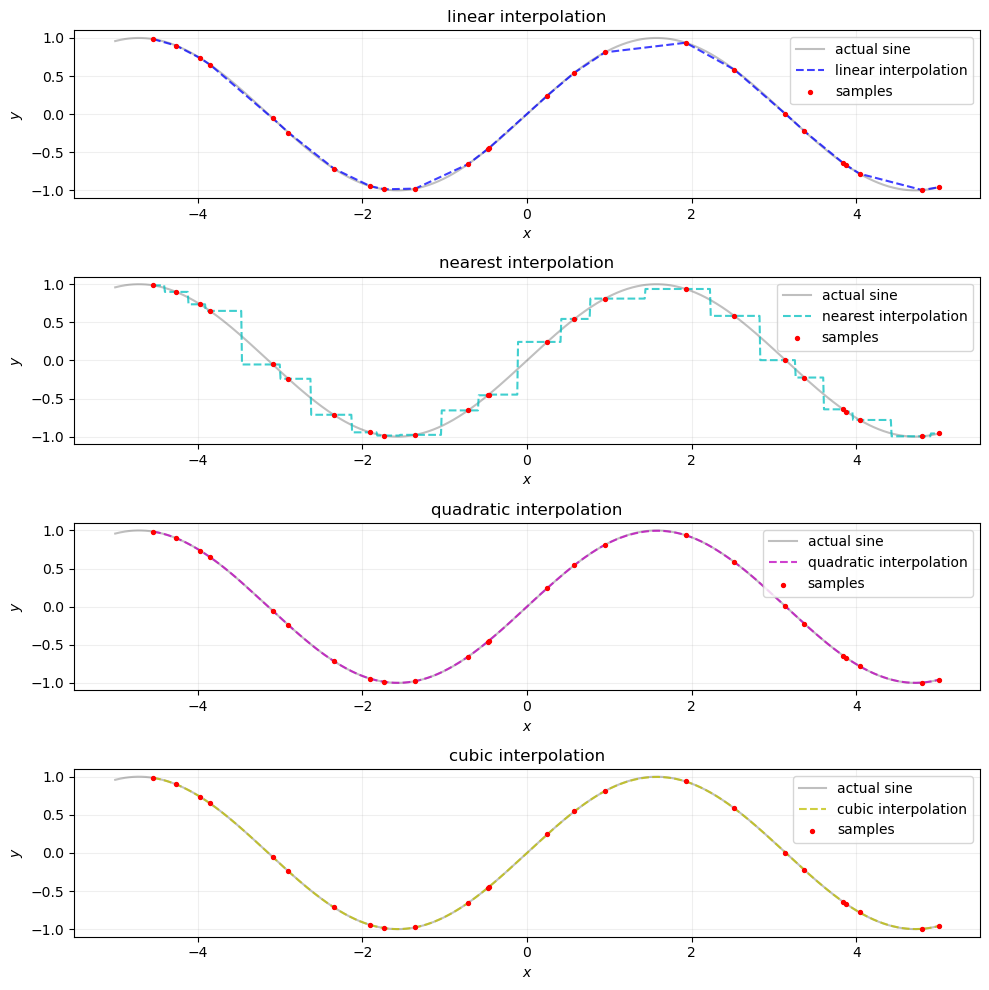

In [3]:
n = 25
x_n = np.random.choice(x, n, replace=False)
y_n = np.sin(x_n)

x_int = np.linspace(np.min(x_n), np.max(x_n), 1000)
methods = ['linear', 'nearest', 'quadratic', 'cubic']
color = ['b', 'c', 'm', 'y']

fig, ax = plt.subplots(4, 1, figsize=(10, 10))
for i, (method, c) in enumerate(zip(methods,color)):
    interpolate = interp1d(x_n, y_n, kind=method)
    ax[i].plot(x, y, color="black", alpha=0.25, label="actual sine", zorder=2)
    ax[i].plot(x_int, interpolate(x_int), linestyle="--", color=c, alpha=0.75, label=f"{method} interpolation",zorder=3)
    ax[i].scatter(x_n, y_n, s=8, color="r", alpha=1, label="samples", zorder=4)
    ax[i].set_title(f"{method} interpolation")
    ax[i].grid(True, alpha=0.2, zorder=1)
    ax[i].legend(loc="upper right")
    ax[i].set_ylabel(r"$y$")
    ax[i].set_xlabel(r"$x$")
plt.tight_layout();

### Problem 2: Interpolation of real-world data

Load the Dow Jones time-series dataset, randomly retain a specified fraction of observations, and compare the reconstructed curve with the original series. The sampling fractions are 50%, 30%, 10%, and 5%. 

In [4]:
# !wget --quiet https://www-personal.umich.edu/~mejn/cp/data/dow.txt

In [5]:
# load the dataset; download it first if needed
# path is https://websites.umich.edu/~mejn/cp/data/dow.txt

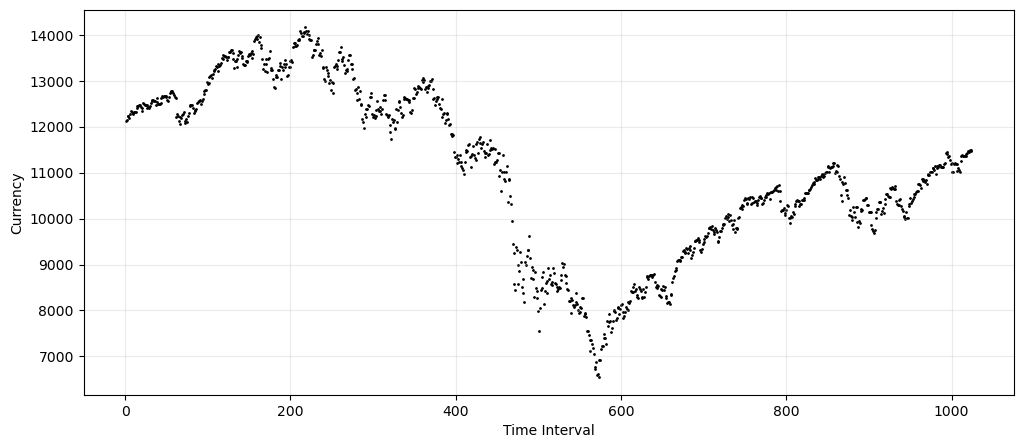

In [6]:
filepath = "dow.txt"
cur = np.loadtxt(filepath)
time = np.arange(1, 1 + np.size(cur))

plt.figure(figsize=(12,5))
plt.scatter(time, cur, s=1, color='black')
plt.xlabel("Time Interval")
plt.ylabel("Currency")
plt.grid(True, alpha=0.25);

In [7]:
methods = ['linear', 'nearest', 'quadratic', 'cubic']
color = ['r', 'c', 'm', 'y']

ns = {
    'n1': (1 + np.size(cur)) // 2,
    'n2': ((1 + np.size(cur)) * 3) // 10,
    'n3': (1 + np.size(cur)) // 10,
    'n4': (1 + np.size(cur)) // 20
}

time_ns = {k: np.random.choice(time, val, replace=False) for k, val in ns.items()}
cur_ns = {k: cur[t_arr-1] for k, t_arr in time_ns.items()}

time_int = {k: np.arange(np.min(v), np.max(v) + 1, 1) for k, v in time_ns.items()}
# instead of using linspace(min, max, min-max+1)

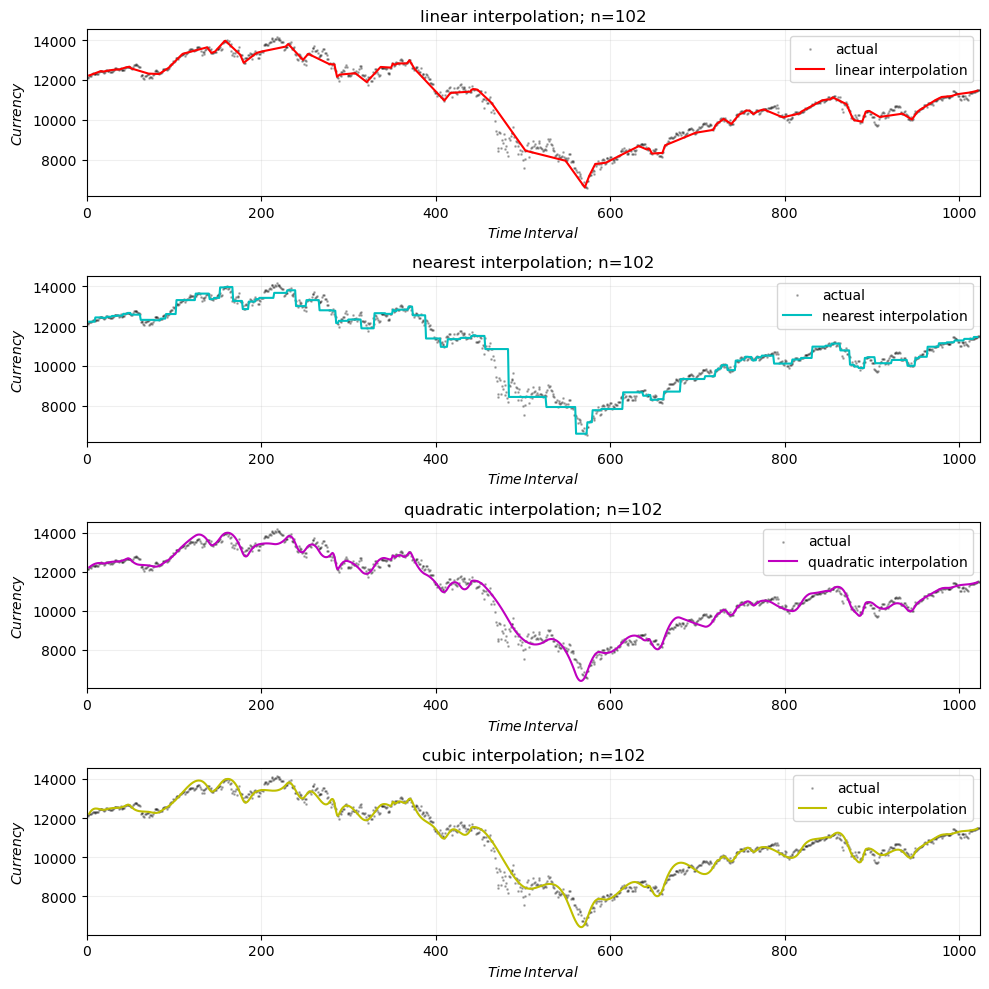

In [8]:
# using 10% only, different methods

fig, dow1 = plt.subplots(4, 1, figsize=(10, 10))
for i, (method, c) in enumerate(zip(methods,color)):
    interpolate = interp1d(time_ns['n3'], cur_ns['n3'], kind=method)
    dow1[i].scatter(time, cur, s=1, color='black', alpha=0.25, label="actual", zorder=2)
    dow1[i].plot(time_int['n3'], interpolate(time_int['n3']), linestyle="-", color=c, alpha=1, label=f"{method} interpolation",zorder=3)
    dow1[i].set_title(f"{method} interpolation; n={len(time_ns['n3'])}")
    dow1[i].grid(True, alpha=0.2, zorder=1)
    dow1[i].legend(loc="upper right")
    dow1[i].set_ylabel(r"$Currency$")
    dow1[i].set_xlabel(r"$Time\,Interval$")
    dow1[i].set_xlim(0,1024)
plt.tight_layout();

### Problem 3: Compare interpolation methods on the sampled real-world data

Use a single sampling fraction to compare linear, quadratic, and cubic interpolation. Higher-order interpolation can produce smoother curves, but it can also overshoot between sparse or rapidly changing observations.

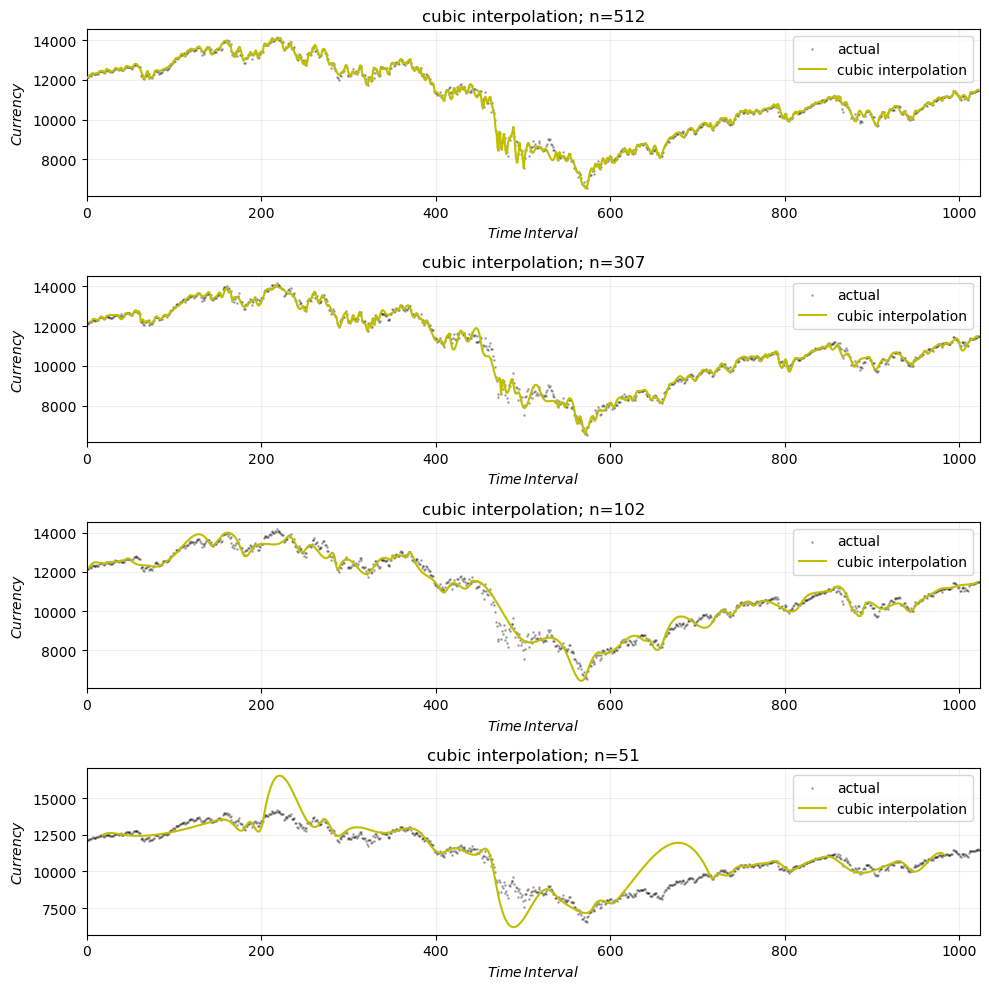

In [9]:
#using cubic, different fractions

fig, dow2 = plt.subplots(4, 1, figsize=(10, 10))
for i, (key, size) in enumerate(ns.items()):
    interpolate = interp1d(time_ns[key], cur_ns[key], kind='cubic')
    dow2[i].scatter(time, cur, s=1, color='black', alpha=0.25, zorder=2, label="actual")
    dow2[i].plot(time_int[key], interpolate(time_int[key]), linestyle="-", color='y', alpha=1, label=f"cubic interpolation",zorder=3)
    dow2[i].set_title(f"cubic interpolation; n={size}")
    dow2[i].grid(True, alpha=0.2, zorder=1)
    dow2[i].legend(loc="upper right")
    dow2[i].set_ylabel(r"$Currency$")
    dow2[i].set_xlabel(r"$Time\,Interval$")
    dow2[i].set_xlim(0,1024)
plt.tight_layout();

### Problem  code summary


I used 'interp1d()' to compute the interpolations (it features a 'kind' parameter that keeps the script concise). The minimum and maximum bounds of the interpolation are based on the samples. For real-world data, since the dataset lacks intermediate values between the raw points (unlike synthetic data), the interpolation step size must match the raw data's (1 time interval unit).

---